# Recorte cuadrado de rostros
Detecta el rostro, centra un recorte cuadrado ajustado al tama?o del rostro y elimina el fondo mediante una m?scara de forma ovalada.


In [1]:
%pip install --quiet --upgrade "opencv-python==4.12.0.88" Pillow numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import cv2
from pathlib import Path
from PIL import Image
import numpy as np

ENTRADA = Path.cwd() / "Will Smith"
SALIDA = Path.cwd() / "Will Smith recortadas"
SALIDA.mkdir(parents=True, exist_ok=True)

# Márgenes relativos al tamaño de cada cara detectada.
PADDING_X = -0.10
PADDING_Y_SUPERIOR = 0.08
PADDING_Y_INFERIOR = 0.04

clasificador = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
if clasificador.empty():
    raise RuntimeError("No se pudo cargar el clasificador de OpenCV")

imagenes = sorted([p for p in ENTRADA.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]) if ENTRADA.exists() else []
print(f"Se encontraron {len(imagenes)} im?genes en {ENTRADA}")

Se encontraron 100 im?genes en f:\7mo Semestre  Tec\Inteligencia Artificial\UNIDAD 2\Fotos proyecto\Codigo\Will Smith


In [12]:
# Valores adaptables: funcionan aunque solo se haya ejecutado esta celda.
PADDING_X = globals().get("PADDING_X", -0.10)
PADDING_Y_SUPERIOR = globals().get("PADDING_Y_SUPERIOR", 0.08)
PADDING_Y_INFERIOR = globals().get("PADDING_Y_INFERIOR", 0.04)

procesadas = 0
sin_deteccion = []

for ruta in imagenes:
    imagen = cv2.imread(str(ruta))
    if imagen is None:
        sin_deteccion.append(ruta.name + " (lectura fallida)")
        continue

    alto_imagen, ancho_imagen = imagen.shape[:2]
    gris = cv2.equalizeHist(cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY))

    caras = clasificador.detectMultiScale(gris, scaleFactor=1.05, minNeighbors=4, minSize=(70, 70))
    if len(caras) == 0:
        caras = clasificador.detectMultiScale(gris, scaleFactor=1.1, minNeighbors=3, minSize=(50, 50))
    if len(caras) == 0:
        sin_deteccion.append(ruta.name)
        continue

    # Deja solo la cara mas grande.
    x, y, w, h = max(caras, key=lambda rect: rect[2] * rect[3])

    # Rect?ngulo adaptado individualmente al tama?o y posici?n detectados.
    margen_x = int(w * PADDING_X)
    margen_superior = int(h * PADDING_Y_SUPERIOR)
    margen_inferior = int(h * PADDING_Y_INFERIOR)

    x1 = max(0, x - margen_x)
    x2 = min(ancho_imagen, x + w + margen_x)
    # Haar frontal detector starts above the eyebrows; shift into the face and below the hair.
    y1 = max(0, y + int(h * 0.18))
    y2 = min(alto_imagen, y + int(h * 0.92) + margen_inferior)

    recorte = imagen[y1:y2, x1:x2].copy()
    if recorte.size == 0:
        sin_deteccion.append(ruta.name + " (recorte vacio)")
        continue

    # Se conserva el tama?o relativo de cada recorte; solo se elimina parte del fondo.
    cv2.imwrite(str(SALIDA / (ruta.stem + "_rostro.png")), recorte)
    procesadas += 1

print(f"Procesadas: {procesadas}")
print(f"Sin deteccion ({len(sin_deteccion)}):")
print(chr(10).join(sin_deteccion[:20]))

Procesadas: 91
Sin deteccion (9):
030_df8c8fad.jpg
036_8751d89b.jpg
055_f9cbb53e.jpg
058_38b80eed.jpg
062_07fcfec7.jpg
065_5cb55293.jpg
072_4a17b7fb.jpg
084_0d8b77bc.jpg
086_bd951ea7.jpg


rostro_001_rostro.png


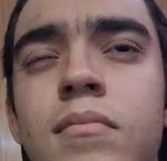

rostro_002_rostro.png


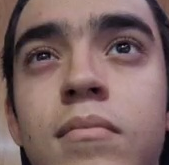

rostro_003_rostro.png


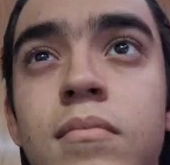

rostro_004_rostro.png


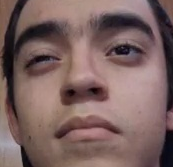

rostro_005_rostro.png


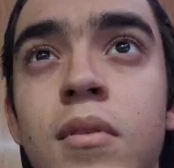

rostro_006_rostro.png


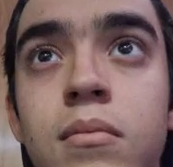

rostro_007_rostro.png


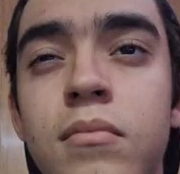

rostro_008_rostro.png


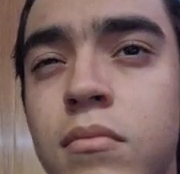

rostro_009_rostro.png


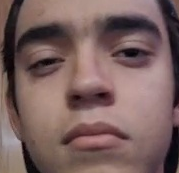

rostro_010_rostro.png


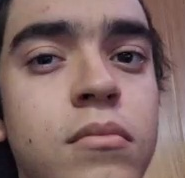

rostro_011_rostro.png


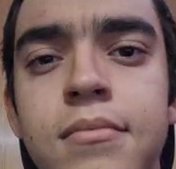

rostro_012_rostro.png


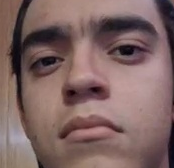

rostro_013_rostro.png


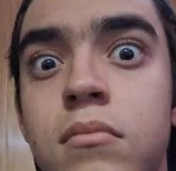

rostro_014_rostro.png


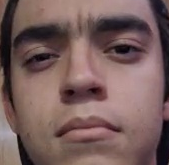

rostro_015_rostro.png


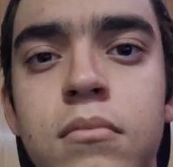

rostro_016_rostro.png


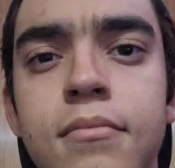

rostro_017_rostro.png


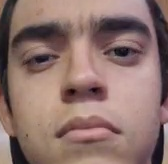

rostro_018_rostro.png


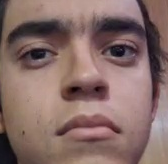

rostro_019_rostro.png


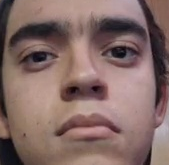

rostro_020_rostro.png


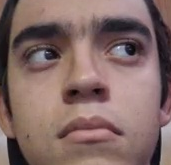

rostro_021_rostro.png


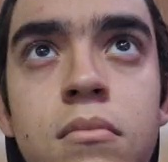

rostro_022_rostro.png


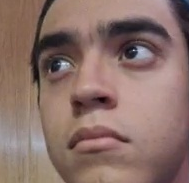

rostro_023_rostro.png


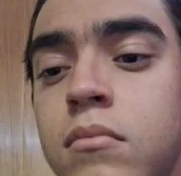

rostro_024_rostro.png


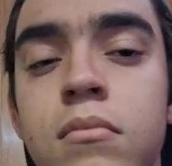

rostro_025_rostro.png


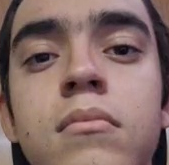

rostro_026_rostro.png


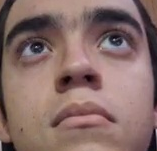

rostro_027_rostro.png


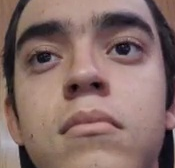

rostro_028_rostro.png


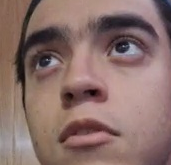

rostro_029_rostro.png


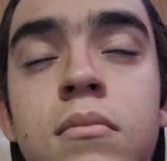

rostro_030_rostro.png


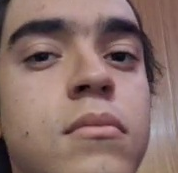

rostro_031_rostro.png


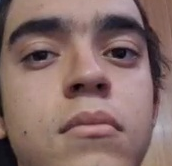

rostro_032_rostro.png


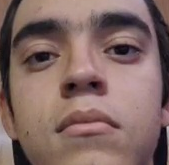

rostro_033_rostro.png


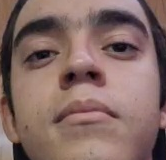

rostro_034_rostro.png


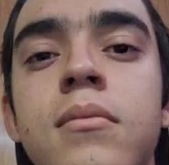

rostro_035_rostro.png


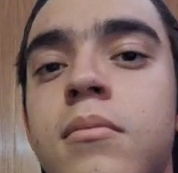

rostro_036_rostro.png


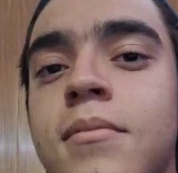

rostro_037_rostro.png


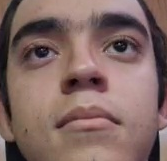

rostro_038_rostro.png


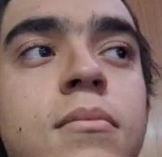

rostro_039_rostro.png


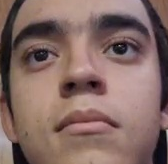

rostro_040_rostro.png


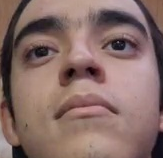

rostro_041_rostro.png


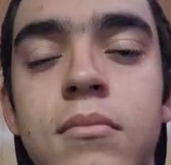

rostro_042_rostro.png


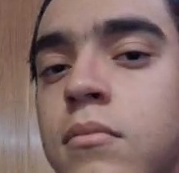

rostro_043_rostro.png


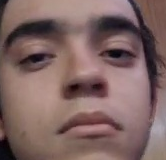

rostro_044_rostro.png


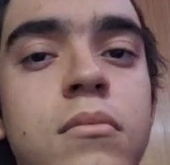

rostro_045_rostro.png


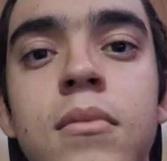

rostro_046_rostro.png


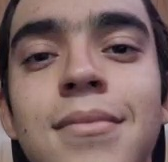

rostro_047_rostro.png


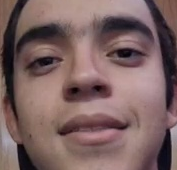

rostro_048_rostro.png


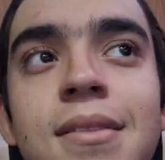

rostro_049_rostro.png


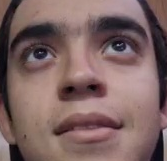

rostro_050_rostro.png


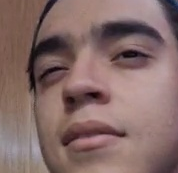

rostro_051_rostro.png


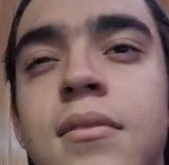

rostro_052_rostro.png


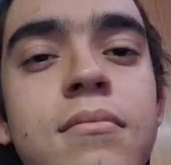

rostro_053_rostro.png


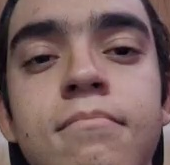

rostro_054_rostro.png


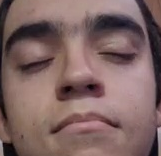

rostro_055_rostro.png


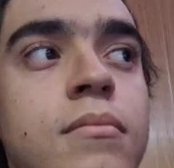

rostro_056_rostro.png


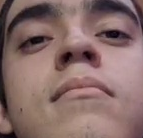

rostro_057_rostro.png


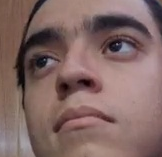

rostro_058_rostro.png


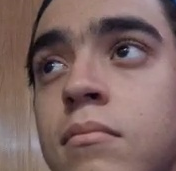

rostro_059_rostro.png


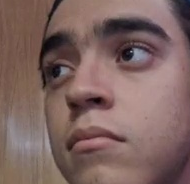

rostro_060_rostro.png


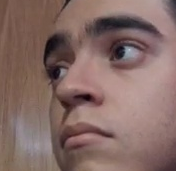

rostro_061_rostro.png


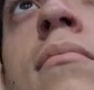

rostro_062_rostro.png


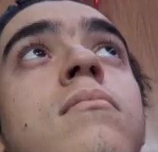

rostro_063_rostro.png


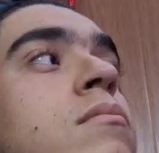

rostro_064_rostro.png


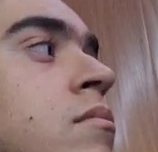

rostro_065_rostro.png


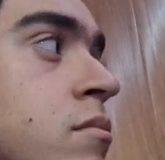

rostro_066_rostro.png


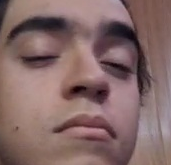

rostro_067_rostro.png


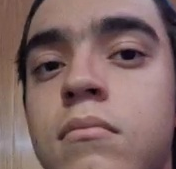

rostro_068_rostro.png


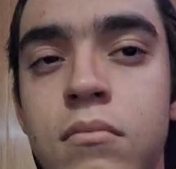

rostro_069_rostro.png


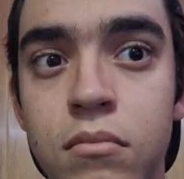

rostro_070_rostro.png


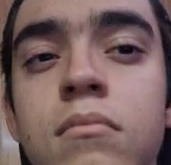

rostro_071_rostro.png


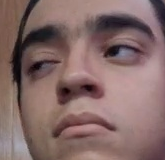

rostro_072_rostro.png


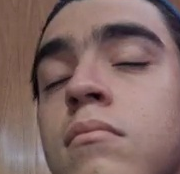

rostro_073_rostro.png


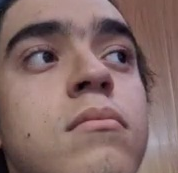

rostro_074_rostro.png


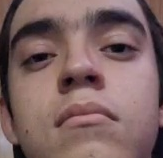

rostro_075_rostro.png


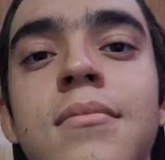

rostro_076_rostro.png


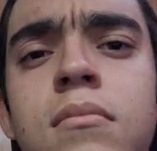

rostro_077_rostro.png


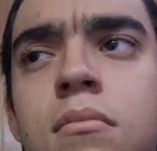

rostro_078_rostro.png


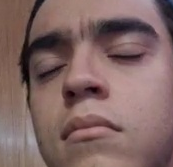

rostro_079_rostro.png


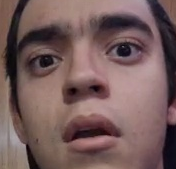

rostro_080_rostro.png


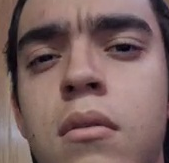

rostro_081_rostro.png


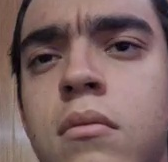

rostro_082_rostro.png


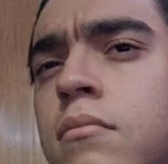

rostro_083_rostro.png


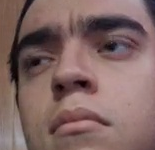

rostro_084_rostro.png


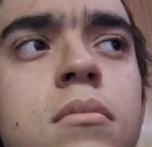

rostro_085_rostro.png


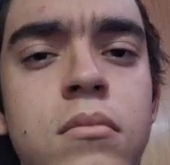

rostro_086_rostro.png


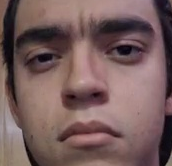

rostro_087_rostro.png


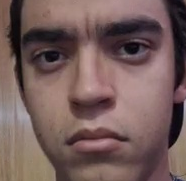

rostro_088_rostro.png


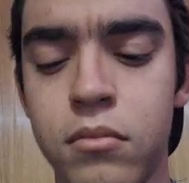

rostro_089_rostro.png


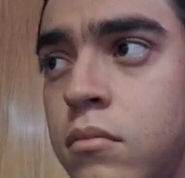

rostro_090_rostro.png


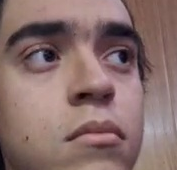

rostro_091_rostro.png


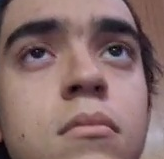

rostro_092_rostro.png


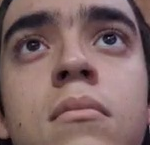

rostro_093_rostro.png


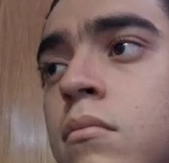

rostro_094_rostro.png


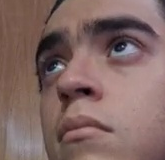

rostro_095_rostro.png


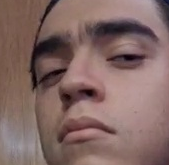

rostro_096_rostro.png


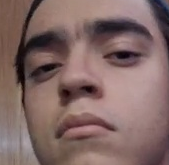

rostro_097_rostro.png


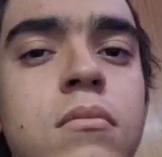

rostro_098_rostro.png


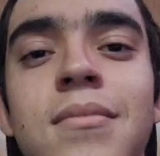

rostro_099_rostro.png


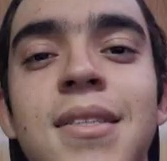

rostro_100_rostro.png


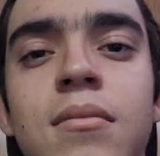

In [16]:
from IPython.display import display
recortados = sorted(SALIDA.glob("*_rostro.png"))
for ruta in recortados[:100]:
    print(ruta.name)
    vista = Image.open(ruta).convert("RGB")
    vista.thumbnail((420, 420))
    display(vista)